In [1]:
%pip install pandas matplotlib seaborn numpy
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams['figure.dpi'] = 120
sns.set_theme(style='whitegrid')

Note: you may need to restart the kernel to use updated packages.


# 03. Surface specialists

A surface is what the court is made of. Clay is slow and the ball bounces high. Grass is fast and the ball stays low. Hard courts sit in between. A surface specialist is a player who wins far more on one surface than on the others. This chapter uses the Slam surface mapping from notebook 01, then checks it against the full tour, where players play many more matches on each surface.

In [2]:
import os
PROC = os.path.join('..', 'data', 'processed')
CH = os.path.join('..', 'charts')
os.makedirs(CH, exist_ok=True)

## Surface Versatility Score, an original metric

Versatility = mean win rate across Clay, Grass and Hard, minus the standard deviation of those three win rates. Standard deviation here just means how spread out the three numbers are. A player who wins a lot and wins evenly scores high. A player who wins a lot on one surface only loses points for the spread. Carpet is left out because it is rare after 2000. Minimum 50 tour matches on each of Clay, Grass and Hard.

In [3]:
surf = pd.read_csv(f'{PROC}/slam_surface_win_rates.csv')
vers = pd.read_csv(f'{PROC}/tour_versatility.csv')
print('Most versatile tour players, 2000 to 2024:')
print(vers.head(10)[['name', 'Clay', 'Grass', 'Hard', 'mean_win_rate', 'std_win_rate', 'versatility']].round(3).to_string(index=False))
for name in ['Rafael Nadal', 'Roger Federer', 'Novak Djokovic']:
    r = vers[vers.name == name].iloc[0]
    print(f"{name}: Clay {r.Clay:.3f}, Grass {r.Grass:.3f}, Hard {r.Hard:.3f}, versatility {r.versatility:.3f}")

Most versatile tour players, 2000 to 2024:
                 name  Clay  Grass  Hard  mean_win_rate  std_win_rate  versatility
       Novak Djokovic 0.806  0.858 0.847          0.837         0.027        0.810
        Roger Federer 0.772  0.878 0.839          0.830         0.053        0.776
         Rafael Nadal 0.902  0.784 0.772          0.819         0.072        0.747
Juan Martin del Potro 0.689  0.690 0.723          0.700         0.020        0.681
          Andy Murray 0.671  0.795 0.738          0.734         0.062        0.672
     Alexander Zverev 0.733  0.661 0.688          0.694         0.036        0.658
         Andy Roddick 0.639  0.798 0.752          0.730         0.082        0.647
       Lleyton Hewitt 0.639  0.761 0.709          0.703         0.061        0.642
        Tomas Berdych 0.637  0.687 0.648          0.657         0.026        0.631
         Milos Raonic 0.625  0.667 0.674          0.655         0.026        0.629
Rafael Nadal: Clay 0.902, Grass 0.784, Hard 

## Chart: Big Three win rates by surface, full tour 2000 to 2024.

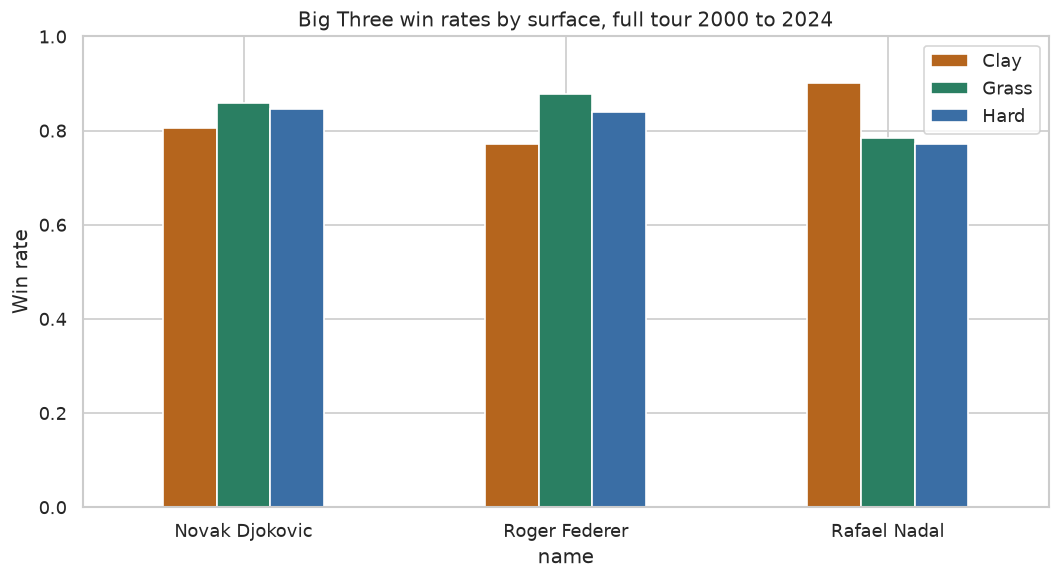

In [4]:
big = vers[vers.name.isin(['Rafael Nadal', 'Roger Federer', 'Novak Djokovic'])].set_index('name')
big[['Clay', 'Grass', 'Hard']].plot(kind='bar', figsize=(9, 5), color=['#b5651d', '#2a7f62', '#3a6ea5'])
plt.title('Big Three win rates by surface, full tour 2000 to 2024'); plt.ylabel('Win rate'); plt.ylim(0, 1); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig(f'{CH}/03_big3_surface_win_rates.png'); plt.show()

## Chart: most versatile players on tour.

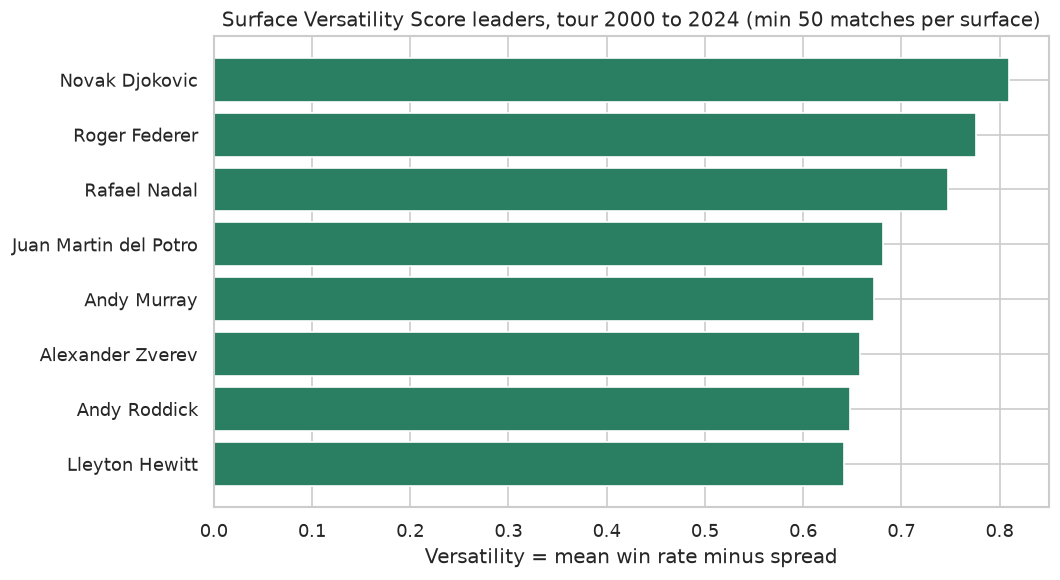

In [5]:
top = vers.head(8)
plt.figure(figsize=(9, 5)); plt.barh(top['name'][::-1], top['versatility'][::-1], color='#2a7f62')
plt.title('Surface Versatility Score leaders, tour 2000 to 2024 (min 50 matches per surface)'); plt.xlabel('Versatility = mean win rate minus spread')
plt.tight_layout(); plt.savefig(f'{CH}/03_versatility_leaders.png'); plt.show()

## Chart: Slam win rates by surface for the same three players, as a check. The story is the same, but the numbers differ because Slams are only the toughest events, not the whole tour.

surface          Clay  Grass   Hard
name                               
Novak Djokovic  0.829  0.878  0.880
Rafael Nadal    0.979  0.815  0.839
Roger Federer   0.814  0.894  0.869


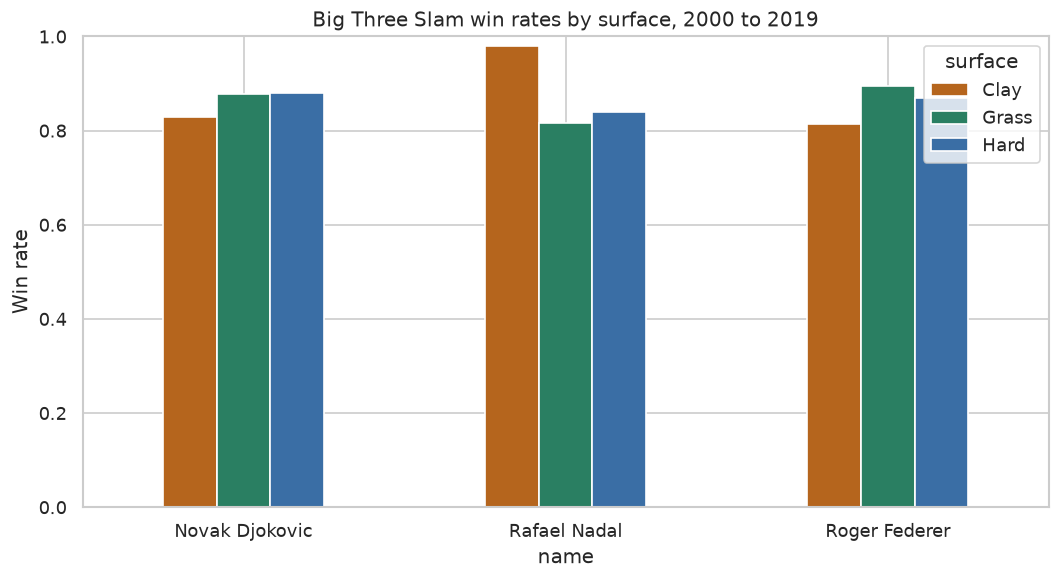

In [6]:
slam_big = surf[surf.name.isin(['Rafael Nadal', 'Roger Federer', 'Novak Djokovic'])]
piv = slam_big.pivot(index='name', columns='surface', values='win_rate')
print(piv.round(3))
piv.plot(kind='bar', figsize=(9, 5), color=['#b5651d', '#2a7f62', '#3a6ea5'])
plt.title('Big Three Slam win rates by surface, 2000 to 2019'); plt.ylabel('Win rate'); plt.ylim(0, 1); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig(f'{CH}/03_big3_slam_surface.png'); plt.show()

## Reading the result honestly

Nadal is the clear clay specialist: 0.902 on clay on tour, against 0.784 on grass and 0.772 on hard. Federer is the grass leader at 0.878. Djokovic leads versatility at 0.810, because he is strong everywhere and his three surfaces are close together. Versatility rewards balance, so it is not the same as being the best on one surface.